### Tensorflow and Keras

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.applications.xception import decode_predictions

In [2]:
path = '../07-Neural Networks and Deep Learning/clothing-dataset-small/train/t-shirt'
name = '5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg'
full_path = f"{path}/{name}"
img = load_img(full_path, target_size=(299, 299))

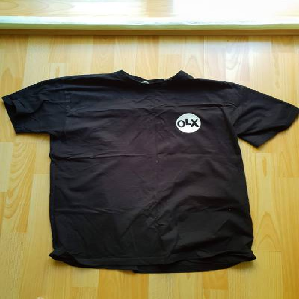

In [3]:
img

In [4]:
print(img)

<PIL.Image.Image image mode=RGB size=299x299 at 0x1CED48E1BE0>


In [5]:
x = np.array(img)

In [6]:
x.shape

(299, 299, 3)

In [7]:
x

array([[[179, 171,  99],
        [179, 171,  99],
        [181, 173, 101],
        ...,
        [251, 253, 248],
        [251, 253, 248],
        [251, 254, 247]],

       [[188, 179, 112],
        [187, 178, 111],
        [186, 177, 108],
        ...,
        [251, 252, 247],
        [251, 252, 247],
        [251, 252, 246]],

       [[199, 189, 127],
        [200, 190, 128],
        [200, 191, 126],
        ...,
        [250, 251, 245],
        [250, 251, 245],
        [250, 251, 245]],

       ...,

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [183, 135,  25],
        [181, 133,  22],
        [183, 135,  24]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [182, 134,  23],
        [180, 132,  21],
        [182, 134,  23]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [181, 133,  22],
        [179, 131,  20],
        [182, 134,  23]]

#### Pre-trained CNN

In [8]:
model = Xception(weights='imagenet', input_shape=(299, 299, 3))

In [9]:
X = np.expand_dims(x, axis=0)       # (1, 299, 299, 3)
X = preprocess_input(X)

In [10]:
X[0]

array([[[ 0.4039216 ,  0.3411765 , -0.2235294 ],
        [ 0.4039216 ,  0.3411765 , -0.2235294 ],
        [ 0.41960788,  0.35686278, -0.20784312],
        ...,
        [ 0.96862745,  0.9843137 ,  0.94509804],
        [ 0.96862745,  0.9843137 ,  0.94509804],
        [ 0.96862745,  0.99215686,  0.9372549 ]],

       [[ 0.47450984,  0.4039216 , -0.12156862],
        [ 0.4666667 ,  0.39607847, -0.12941176],
        [ 0.45882356,  0.38823533, -0.15294117],
        ...,
        [ 0.96862745,  0.9764706 ,  0.9372549 ],
        [ 0.96862745,  0.9764706 ,  0.9372549 ],
        [ 0.96862745,  0.9764706 ,  0.92941177]],

       [[ 0.56078434,  0.48235297, -0.00392157],
        [ 0.5686275 ,  0.4901961 ,  0.00392163],
        [ 0.5686275 ,  0.49803925, -0.01176471],
        ...,
        [ 0.9607843 ,  0.96862745,  0.92156863],
        [ 0.9607843 ,  0.96862745,  0.92156863],
        [ 0.9607843 ,  0.96862745,  0.92156863]],

       ...,

       [[ 0.2941177 ,  0.18431377, -0.40392154],
        [ 0

In [11]:
pred = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 47s 47s/step


In [12]:
decode_predictions(pred, top=3)

[[('n03595614', 'jersey', np.float32(0.68196434)),
  ('n02916936', 'bulletproof_vest', np.float32(0.038139872)),
  ('n04370456', 'sweatshirt', np.float32(0.034324642))]]

#### Transfer Learning

In [13]:
train_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

In [14]:
train_ds = train_gen.flow_from_directory('../07-Neural Networks and Deep Learning/clothing-dataset-small/train', target_size=(150, 150), batch_size=32)

Found 3068 images belonging to 10 classes.


In [15]:
train_ds.class_indices

{'dress': 0,
 'hat': 1,
 'longsleeve': 2,
 'outwear': 3,
 'pants': 4,
 'shirt': 5,
 'shoes': 6,
 'shorts': 7,
 'skirt': 8,
 't-shirt': 9}

In [16]:
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)
val_ds = val_gen.flow_from_directory('../07-Neural Networks and Deep Learning/clothing-dataset-small/validation', 
                                     target_size=(150, 150), 
                                     batch_size=32, 
                                     shuffle=False)

Found 341 images belonging to 10 classes.


In [17]:
base_model = Xception(weights='imagenet', include_top=False, input_shape=(150, 150, 3))
base_model.trainable = False

In [18]:
inputs = keras.Input(shape=(150, 150, 3))
base = base_model(inputs)
vectors = keras.layers.GlobalAveragePooling2D()(base)
outputs = keras.layers.Dense(10)(vectors)
model = keras.Model(inputs, outputs)

In [19]:
learning_rate = 0.01
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
loss = keras.losses.CategoricalCrossentropy(from_logits=True)

In [20]:
model.compile(optimizer=optimizer, loss=loss, metrics=["accuracy"])

In [21]:
history = model.fit(train_ds, epochs = 10, validation_data=val_ds)

Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 84s 816ms/step - accuracy: 0.6786 - loss: 1.2039 - val_accuracy: 0.7830 - val_loss: 0.8101
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 66s 682ms/step - accuracy: 0.8253 - loss: 0.5334 - val_accuracy: 0.7507 - val_loss: 1.0546
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 58s 601ms/step - accuracy: 0.8856 - loss: 0.3259 - val_accuracy: 0.7947 - val_loss: 0.8687
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 53s 547ms/step - accuracy: 0.9097 - loss: 0.2544 - val_accuracy: 0.7918 - val_loss: 0.9001
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 51s 527ms/step - accuracy: 0.9325 - loss: 0.1836 - val_accuracy: 0.7859 - val_loss: 1.0236
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 51s 534ms/step - accuracy: 0.9563 - loss: 0.1250 - val_accuracy: 0.7889 - val_loss: 1.0033
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 55s 576ms/step - accuracy: 0.9756 - loss: 0.0791 - val_accuracy: 0.8006 - val_loss: 0.8841
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 55s 569ms/step - accuracy: 0.9690 - loss: 0.0873 - val_accu

#### Adjusting the learning rate

In [22]:
def make_model(learning_rate):
    base_model = Xception(weights='imagenet', 
                          include_top=False, 
                          input_shape=(150, 150, 3))
    base_model.trainable = False

    #####################################################################
    
    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    outputs = keras.layers.Dense(10)(vectors)
    model = keras.Model(inputs, outputs)

    #####################################################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)
    
    model.compile(optimizer=optimizer, 
                  loss=loss, 
                  metrics=['accuracy'])
    return model

In [23]:
scores = {}

for learning_rate in [0.0001, 0.001, 0.01, 0.1]:
    model = make_model(learning_rate)
    history = model.fit(train_ds, 
                        validation_data=val_ds, 
                        epochs=10)
    scores[learning_rate] = history.history

for learning_rate, history in scores.items():
    val_accuracy = history['val_accuracy'][-1]
    print(f"Learning rate: {learning_rate}, Validation Accuracy: {val_accuracy}")

Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 55s 557ms/step - accuracy: 0.3449 - loss: 1.9409 - val_accuracy: 0.4604 - val_loss: 1.6181
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 50s 526ms/step - accuracy: 0.5610 - loss: 1.3939 - val_accuracy: 0.5865 - val_loss: 1.2697
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 51s 528ms/step - accuracy: 0.6415 - loss: 1.1505 - val_accuracy: 0.6628 - val_loss: 1.0910
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 43s 450ms/step - accuracy: 0.6845 - loss: 1.0105 - val_accuracy: 0.6833 - val_loss: 0.9835
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 53s 557ms/step - accuracy: 0.7099 - loss: 0.9161 - val_accuracy: 0.7038 - val_loss: 0.9067
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 57s 595ms/step - accuracy: 0.7285 - loss: 0.8478 - val_accuracy: 0.7331 - val_loss: 0.8529
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 56s 586ms/step - accuracy: 0.7461 - loss: 0.7945 - val_accuracy: 0.7361 - val_loss: 0.8102
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 56s 589ms/step - accuracy: 0.7585 - loss: 0.7493 - val_accu